# Data Science avec Pandas : les concepts clés

Notebook de l'article [Data Science avec Pandas](https://moncoachdata.com/blog/data-science-avec-pandas/) de MonCoachData. Données : [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/dgoenrique/netflix-movies-and-tv-shows) (Kaggle). Code testé avec Python 3.13 et Pandas 3.

## Télécharger les données

Les deux fichiers CSV sont téléchargés depuis GitHub (rien n'est téléchargé s'ils sont déjà présents).

In [1]:
import os
from urllib.request import urlretrieve

for fichier in ("titles.csv", "credits.csv"):
    if not os.path.exists(fichier):
        urlretrieve(
            "https://raw.githubusercontent.com/moncoachdata/blog-data-science/main/data-science-avec-pandas/" + fichier,
            fichier,
        )

## Importer Pandas

In [2]:
import pandas as pd

print(pd.__version__)

2.2.3


## Lire les fichiers CSV

In [3]:
netflix_titles = pd.read_csv("titles.csv")
netflix_credits = pd.read_csv("credits.csv")

print(netflix_titles.shape)
print(netflix_credits.shape)

(6137, 15)
(81355, 5)


## Observer les données

Les 5 premières lignes des titres.

In [4]:
pd.set_option("display.max_columns", 8)
netflix_titles.head()

,id,title,type,description,...,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,...,NaN,NaN,0.601,NaN
1,tm82169,Rocky,MOVIE,"When world heavyweight boxing champion, Apollo...",...,8.1,588100.0,106.361,7.782
2,tm17823,Grease,MOVIE,Australian good girl Sandy and greaser Danny f...,...,7.2,283316.0,33.160,7.406
3,tm191099,The Sting,MOVIE,A novice con man teams up with an acknowledged...,...,8.3,266738.0,24.616,8.020
4,tm69975,Rocky II,MOVIE,After Rocky goes the distance with champ Apoll...,...,7.3,216307.0,75.699,7.246


Le générique : une ligne par personne et par titre.

In [5]:
netflix_credits.head()

,person_id,id,name,character,role
0,3180,tm82169,Sylvester Stallone,"Robert ""Rocky"" Balboa",ACTOR
1,7748,tm82169,Talia Shire,"Adrianna ""Adrian"" Pennino",ACTOR
2,7749,tm82169,Burt Young,Paulie Pennino,ACTOR
3,7750,tm82169,Carl Weathers,Apollo Creed,ACTOR
4,7751,tm82169,Burgess Meredith,Mickey Goldmill,ACTOR


`info()` : types des colonnes et valeurs non manquantes.

In [6]:
netflix_titles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6137 entries, 0 to 6136
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    6137 non-null   object 
 1   title                 6137 non-null   object 
 2   type                  6137 non-null   object 
 3   description           6114 non-null   object 
 4   release_year          6137 non-null   int64  
 5   age_certification     3394 non-null   object 
 6   runtime               6137 non-null   int64  
 7   genres                6137 non-null   object 
 8   production_countries  6137 non-null   object 
 9   seasons               2306 non-null   float64
 10  imdb_id               5741 non-null   object 
 11  imdb_score            5669 non-null   float64
 12  imdb_votes            5653 non-null   float64
 13  tmdb_popularity       6061 non-null   float64
 14  tmdb_score            5885 non-null   float64
dtypes: float64(5), int64(

`describe()` : statistiques des colonnes numériques.

In [7]:
netflix_titles[["release_year", "runtime", "imdb_score"]].describe().round(2)

,release_year,runtime,imdb_score
count,6137.00,6137.00,5669.00
mean,2017.37,76.38,6.54
std,6.60,39.09,1.14
min,1945.00,0.00,1.50
25%,2017.00,44.00,5.80
50%,2019.00,80.00,6.60
75%,2021.00,105.00,7.30
max,2023.00,225.00,9.60


## Sélectionner des colonnes et des lignes

Une colonne : le résultat est une Series.

In [8]:
netflix_titles["description"]

,description
0,This collection includes 12 World War II-era p...
1,"When world heavyweight boxing champion, Apollo..."
2,Australian good girl Sandy and greaser Danny f...
3,A novice con man teams up with an acknowledged...
4,After Rocky goes the distance with champ Apoll...
...,...
6132,Two young boys must work together to stop robb...
6133,"‘Theatre is my life,’ Yıldız Kenter admits in ..."
6134,This Queen of Comedy shines as she takes the s...
6135,The lives of three teenagers and a hit-man int...


Plusieurs colonnes : le résultat est un DataFrame.

In [9]:
netflix_titles[["title", "description"]]

,title,description
0,Five Came Back: The Reference Films,This collection includes 12 World War II-era p...
1,Rocky,"When world heavyweight boxing champion, Apollo..."
2,Grease,Australian good girl Sandy and greaser Danny f...
3,The Sting,A novice con man teams up with an acknowledged...
4,Rocky II,After Rocky goes the distance with champ Apoll...
...,...,...
6132,عبود في البيت,Two young boys must work together to stop robb...
6133,Sweetie,"‘Theatre is my life,’ Yıldız Kenter admits in ..."
6134,Sommore: Queen Chandelier,This Queen of Comedy shines as she takes the s...
6135,All Na Vibes,The lives of three teenagers and a hit-man int...


`loc` (étiquettes) et `iloc` (positions).

In [10]:
print(netflix_titles.loc[0, "title"])
print(netflix_titles.iloc[2, 1])
netflix_titles.loc[:3, ["title", "type", "release_year"]]

Five Came Back: The Reference Films
Grease


,title,type,release_year
0,Five Came Back: The Reference Films,SHOW,1945
1,Rocky,MOVIE,1976
2,Grease,MOVIE,1978
3,The Sting,MOVIE,1973


## Filtrer

Une condition entre crochets.

In [11]:
bien_notes = netflix_titles[netflix_titles["imdb_score"] > 8]

print(len(bien_notes), "titres avec une note IMDB supérieure à 8")
bien_notes[["title", "type", "release_year", "imdb_score"]].head()

425 titres avec une note IMDB supérieure à 8


,title,type,release_year,imdb_score
1,Rocky,MOVIE,1976,8.1
3,The Sting,MOVIE,1973,8.3
5,Monty Python and the Holy Grail,MOVIE,1975,8.2
7,Monty Python's Flying Circus,SHOW,1969,8.8
13,Richard Pryor: Live in Concert,MOVIE,1979,8.1


Plusieurs conditions : `&`, `|`, `~`, avec des parenthèses.

In [12]:
films_cultes = netflix_titles[
    (netflix_titles["type"] == "MOVIE") & (netflix_titles["imdb_score"] > 8.5)
]

print(len(films_cultes), "films avec une note supérieure à 8,5")
films_cultes[["title", "release_year", "imdb_score"]].sort_values("imdb_score", ascending=False).head()

18 films avec une note supérieure à 8,5


,title,release_year,imdb_score
209,The Lord of the Rings: The Return of the King,2003,9.0
201,The Dark Knight,2008,9.0
4758,Split at the Root,2022,8.9
3215,David Attenborough: A Life on Our Planet,2020,8.9
195,The Lord of the Rings: The Fellowship of the Ring,2001,8.8


`query()` : la même chose, de façon plus lisible.

In [13]:
same = netflix_titles.query("type == 'MOVIE' and imdb_score > 8.5")

print(same.equals(films_cultes))

True


## Agréger avec groupby

Nombre de titres par type.

In [14]:
netflix_titles.groupby(["type"]).agg(title_count=("title", "count"))

,title_count
type,
MOVIE,3831
SHOW,2306


Plusieurs agrégats à la fois.

In [15]:
netflix_titles.groupby("type").agg(
    title_count=("title", "count"),
    imdb_moyen=("imdb_score", "mean"),
    duree_mediane=("runtime", "median"),
).round(2)

,title_count,imdb_moyen,duree_mediane
type,,,
MOVIE,3831,6.27,99.0
SHOW,2306,6.99,42.0


Compter les genres : `ast.literal_eval` puis `explode()`.

In [16]:
import ast

netflix_titles["genres"] = netflix_titles["genres"].apply(ast.literal_eval)   # texte -> vraie liste

genres = netflix_titles.explode("genres")
genres["genres"].value_counts().head(5)

,count
genres,
drama,3120
comedy,2485
thriller,1229
action,1140
romance,1054


## Valeurs manquantes

Compter les valeurs manquantes par colonne.

In [17]:
netflix_titles.isna().sum()

,0
id,0
title,0
type,0
description,23
release_year,0
age_certification,2743
runtime,0
genres,0
production_countries,0
seasons,3831


`fillna()` : un film n'a pas de saison, donc 0.

In [18]:
netflix_titles["seasons"] = netflix_titles["seasons"].fillna(0)

print(netflix_titles["seasons"].isna().sum(), "valeurs manquantes dans seasons")
print(netflix_titles.groupby("type")["seasons"].agg(["min", "max"]))

0 valeurs manquantes dans seasons
       min   max
type            
MOVIE  0.0   0.0
SHOW   1.0  44.0


`dropna(subset=...)` : supprimer les lignes sans note IMDB.

In [19]:
avec_note = netflix_titles.dropna(subset=["imdb_score"])

print(len(netflix_titles), "titres avant,", len(avec_note), "après dropna sur imdb_score")

6137 titres avant, 5669 après dropna sur imdb_score


## Trier

Ordre croissant.

In [20]:
# trier les données en fonction de l'année de publication
netflix_titles.sort_values("release_year")[["title", "type", "release_year"]].head()

,title,type,release_year
0,Five Came Back: The Reference Films,SHOW,1945
27,The Blazing Sun,MOVIE,1954
9,White Christmas,MOVIE,1954
26,Dark Waters,MOVIE,1956
12,Cairo Station,MOVIE,1958


Plusieurs colonnes, avec des ordres différents.

In [21]:
# année de sortie puis note IMDB, tous deux dans l'ordre décroissant
netflix_titles.sort_values(
    ["release_year", "imdb_score"], ascending=[False, False]
)[["title", "release_year", "imdb_score"]].head()

,title,release_year,imdb_score
6104,Nanpakal Nerathu Mayakkam,2023,8.8
6113,Black Sunshine Baby,2023,8.5
6120,Rekha,2023,8.4
6129,Thalaikoothal,2023,8.4
6043,Full Swing,2023,8.2


## Fusionner avec merge

Inner join : seulement les titres présents dans les deux tables.

In [22]:
# fusionner les DataFrames sur la base de la colonne "id"
joined_df = pd.merge(netflix_titles, netflix_credits, on="id", how="inner")

print(joined_df.shape)
joined_df[["title", "type", "name", "role"]].head()

(81355, 19)


,title,type,name,role
0,Rocky,MOVIE,Sylvester Stallone,ACTOR
1,Rocky,MOVIE,Talia Shire,ACTOR
2,Rocky,MOVIE,Burt Young,ACTOR
3,Rocky,MOVIE,Carl Weathers,ACTOR
4,Rocky,MOVIE,Burgess Meredith,ACTOR


Left join avec `indicator=True` : on garde aussi les titres sans générique.

In [23]:
avec_indicateur = pd.merge(
    netflix_titles, netflix_credits, on="id", how="left", indicator=True
)

sans_generique = avec_indicateur[avec_indicateur["_merge"] == "left_only"]
print(len(sans_generique), "titres sans aucune ligne dans credits")
print(len(avec_indicateur), "lignes avec un left join, contre", len(joined_df), "avec un inner join")

349 titres sans aucune ligne dans credits
81704 lignes avec un left join, contre 81355 avec un inner join


Attention : après la fusion, un titre apparaît autant de fois qu'il a de personnes au générique.

In [24]:
credits_par_titre = netflix_credits.groupby("id").size()

print(credits_par_titre.describe().round(1))
print(joined_df["id"].nunique(), "titres distincts dans joined_df")

count    5788.0
mean       14.1
std        14.5
min         1.0
25%         5.0
50%        10.0
75%        18.0
max       209.0
dtype: float64
5788 titres distincts dans joined_df


## Appliquer une fonction

`apply()` avec une lambda, comparé à l'opération vectorisée.

In [25]:
# convertir la durée en heures avec apply et lambda
joined_df["runtime_hours"] = joined_df["runtime"].apply(lambda x: x / 60)

# la même opération, vectorisée
runtime_hours_vec = joined_df["runtime"] / 60

print(joined_df["runtime_hours"].equals(runtime_hours_vec))
joined_df[["title", "runtime", "runtime_hours"]].head()

True


,title,runtime,runtime_hours
0,Rocky,119,1.983333
1,Rocky,119,1.983333
2,Rocky,119,1.983333
3,Rocky,119,1.983333
4,Rocky,119,1.983333


## Visualiser

Histogramme du nombre de personnes au générique par titre.

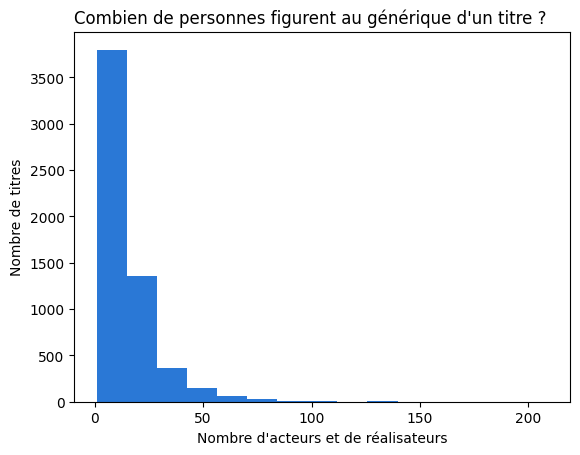

10.0 personnes au générique pour un titre médian


In [26]:
import matplotlib.pyplot as plt

role_count = joined_df.groupby("id").agg(count_role=("role", "count")).reset_index()

plt.hist(role_count["count_role"], bins=15, color="#2a78d6")
plt.xlabel("Nombre d'acteurs et de réalisateurs")
plt.ylabel("Nombre de titres")
plt.title("Combien de personnes figurent au générique d'un titre ?", loc="left")
plt.show()

print(role_count["count_role"].median(), "personnes au générique pour un titre médian")

Nombre de films et de séries par année de sortie. L'année 2023 est incomplète dans ce jeu de données.

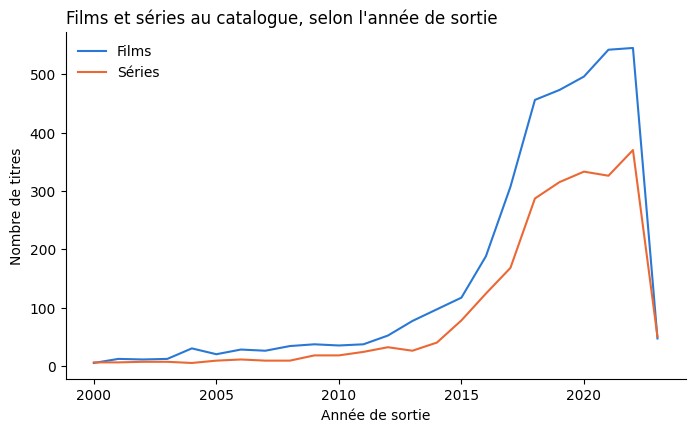

type          MOVIE  SHOW
release_year             
2000              5     6
2010             35    18
2020            496   333


In [27]:
par_annee = (
    netflix_titles[netflix_titles["release_year"] >= 2000]
    .groupby(["release_year", "type"])
    .size()
    .unstack("type")
)

ax = par_annee.plot(color={"MOVIE": "#2a78d6", "SHOW": "#eb6834"}, figsize=(8, 4.5))
ax.set_xlabel("Année de sortie")
ax.set_ylabel("Nombre de titres")
ax.set_title("Films et séries au catalogue, selon l'année de sortie", loc="left")
ax.legend(["Films", "Séries"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(par_annee.loc[[2000, 2010, 2020]])

## Dates

Convertir l'année en date, l'utiliser comme index, puis sélectionner une période.

In [28]:
titres_dates = netflix_titles.assign(
    release_date=pd.to_datetime(netflix_titles["release_year"].astype(str), format="%Y")
).set_index("release_date").sort_index()

print(titres_dates.index.dtype)
titres_dates.loc["2018":"2020", ["title", "type"]].head()

datetime64[ns]


,title,type
release_date,,
2018-01-01,FIGHTWORLD,SHOW
2018-01-01,AMO,SHOW
2018-01-01,Paradox,MOVIE
2018-01-01,Drug Lords,SHOW
2018-01-01,BuyBust,MOVIE


`resample()` : regrouper par tranches de 5 ans.

In [29]:
# nombre de titres par période de 5 ans
titres_dates["id"].resample("5YS").count().tail(6)

,id
release_date,
1995-01-01,60
2000-01-01,101
2005-01-01,201
2010-01-01,438
2015-01-01,2513
2020-01-01,2709


Le même principe sur des dates quotidiennes.

In [30]:
dates = pd.date_range("2023-01-01", periods=10)
df = pd.DataFrame({"A": range(1, 11), "B": range(11, 21)}, index=dates)

print(df.loc["2023-01-03":"2023-01-07"])
print(df.resample("W").mean())

            A   B
2023-01-03  3  13
2023-01-04  4  14
2023-01-05  5  15
2023-01-06  6  16
2023-01-07  7  17
              A     B
2023-01-01  1.0  11.0
2023-01-08  5.0  15.0
2023-01-15  9.5  19.5
